### Analysing Standard Property Transactions in the UK Housing Market

This project investigates standard residential property transaction trends within the UK housing market for the year 2024, using data from the official UK government source (gov.uk). The core objective is to analyse how key features — such as property type, location, and transaction date — influence property prices. By focusing on standard residential sales, this analysis aims to uncover meaningful patterns that reveal how these variables shape market value and contribute to pricing dynamics across regions.

In [1]:
#Ensuring the relevant packages are installed
%pip install geopy

#Importing relevant packages and assigning alliases
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import numpy as np
from geopy.distance import geodesic

Note: you may need to restart the kernel to use updated packages.


### Data Preprocessing

The dataset requires initial cleaning and formatting to ensure it is ready for analysis. This includes assigning meaningful column names, converting coded categorical variables to descriptive labels, and filtering out certain rows to focus exclusively on typical residential sales.

In [2]:
# Load the CSV file without using the first row as the header
property_prices_raw = pd.read_csv('pp-2024.csv', header=None)

# Assign generic column names like column_0, column_1, ..., column_n as a placeholder
property_prices_raw.columns = [f"column_{i}" for i in range(len(property_prices_raw.columns))]

# Display the first 5 rows of the DataFrame to preview the data
property_prices_raw.head()

,column_0,column_1,column_2,column_3,column_4,column_5,column_6,column_7,column_8,column_9,column_10,column_11,column_12,column_13,column_14,column_15
0,{2131FCF5-B031-86E8-E063-4804A8C0372B},320000,2024-07-26 00:00,MK40 3SG,T,N,F,38,NaN,GEORGE STREET,NaN,BEDFORD,BEDFORD,BEDFORD,A,A
1,{2131FCF5-B034-86E8-E063-4804A8C0372B},300000,2024-02-15 00:00,MK43 9GH,S,N,F,12,NaN,BRICK CRESCENT,STEWARTBY,BEDFORD,BEDFORD,BEDFORD,A,A
2,{2131FCF5-B036-86E8-E063-4804A8C0372B},470000,2024-08-21 00:00,MK45 2BF,S,N,F,21,NaN,COLTSFOOT CORNER,AMPTHILL,BEDFORD,CENTRAL BEDFORDSHIRE,CENTRAL BEDFORDSHIRE,A,A
3,{2131FCF5-B037-86E8-E063-4804A8C0372B},527500,2024-07-29 00:00,MK43 0YX,D,N,L,1,NaN,FALLOWS CRESCENT,CRANFIELD,BEDFORD,CENTRAL BEDFORDSHIRE,CENTRAL BEDFORDSHIRE,A,A
4,{2131FCF5-B038-86E8-E063-4804A8C0372B},351000,2024-07-17 00:00,LU3 3AR,T,N,F,320,NaN,SUNDON PARK ROAD,NaN,LUTON,LUTON,LUTON,A,A


The schema for the dataset fields is documented on the official gov.uk website ([Price Paid Data schema](https://www.gov.uk/guidance/about-the-price-paid-data)). I renamed the columns accordingly to align with these definitions, ensuring clarity and consistency throughout the analysis.

In [3]:
property_prices_raw.rename(columns={
    'column_0' : 'Identifier',          #This seems to be a sale identifier. Further investigation needs to be done to ensure this is distinct.
    'column_1' : 'Price',               #Price of property sale. As this is a UK based database, the assumption can be made that this is in GBP (£). 
    'column_2' : 'Date_of_sale',        #This is the date of the sale.
    'column_3' : 'Postcode',            #This is the post code of the property.
    'column_4' : 'Property_type_Code',  #According to gov.uk: D = Detached, S = Semi-Detached, T = Terraced, F = Flats/Maisonettes, O = Other
    'column_5' : 'Old/new_Code',        #Property age, N = 'Old build', Y = 'New build'
    'column_6' : 'Tenure_Code',         #According to gov.uk "F = Freehold, L= Leasehold" Further investigation needed to understand each enumeration.
    'column_7' : 'PAON',                #This is the Primary Addressable Object Name (typically the house number or name) as listed on the gov.uk site.
    'column_8' : 'SAON',                #This is the Secondary Addressable Object Name which will be populated if the property is in a building divided into flats, for example as listed on the gov.uk site.
    'column_9' : 'Street',              #Street name of the property.
    'column_10' : 'Locality',           #Locality of the property.
    'column_11' : 'Town/city',          #Town/City of the property.
    'column_12' : 'District',           #District of the property.
    'column_13' : 'County',             #County of the property.
    'column_14' : 'PPD_category_Code',  #Indicates the type of Price Paid transaction. A=Standard Price Paid. B=Additional Price Paid.
    'column_15' : 'Record_status_Code', #A = Addition, C = Change, D = Delete
}, inplace=True)

Certain things need to be checked to ensure the efficacy and validity of the data. For instance, the Identifier type should be unique and the number of populated SAONs with corresponding unpopulated PAONs should be 0.

In [4]:
#Assuring the identifiers are unique.
print('Number of duplicated Identifiers : ',(property_prices_raw['Identifier'].value_counts() > 1).sum())
#Assuring SAON is only populated if PAON is populated
print('Number of populated SAON and unpopulated PAON : ', ((~property_prices_raw['SAON'].isna()) & (property_prices_raw['PAON'].isna()) == True).sum())

Number of duplicated Identifiers :  0
Number of populated SAON and unpopulated PAON :  0


In [5]:
#Setting identifiers as the index 
property_prices_raw.set_index('Identifier', inplace=True)

To improve readability and interpretability, categorical fields encoded as single-letter codes (e.g., "D" for Detached) are converted to their full descriptive values. This makes visualisations and groupings more meaningful and accessible.

Additionally, the 'Record_status' field is omitted, as it contains metadata unrelated to the property characteristics or pricing — and is therefore not relevant to this analysis.

In [6]:
property_type_map = {
    "D": "Detached",
    "S": "Semi-Detached",
    "T": "Terraced",
    "F": "Flat"
}

old_new_map = {
    "Y": "New Build",
    "N": "Old Build"
}

ppd_category_map = {
    "A": "Standard Price Paid",
    "B": "Additional Price Paid"
}

tenure_map = {
    "F": "Freehold",
    "L": "Leasehold"
}

#Using the mappings above, we create a new categorical variable, replacing the one letter code with the decoded equivalent.
#If the code is not outlined in the above, it is listed as "Other".
property_prices_raw["Property_type"] = property_prices_raw["Property_type_Code"].str.strip().map(property_type_map).fillna("Other")
property_prices_raw["Old/new"] = property_prices_raw["Old/new_Code"].str.strip().map(old_new_map).fillna("Other")
property_prices_raw["PPD"] = property_prices_raw["PPD_category_Code"].str.strip().map(ppd_category_map).fillna("Other")
property_prices_raw["Tenure"] = property_prices_raw["Tenure_Code"].str.strip().map(tenure_map).fillna("Other")

#The coded variables are dropped from the table
property_prices_clean = property_prices_raw.drop(columns=["Property_type_Code", "Old/new_Code", "PPD_category_Code", "Tenure_Code", "Record_status_Code"])

In [7]:
# Define a dictionary that maps column names to their desired data types
# This ensures consistent data formatting and optimises memory usage
dtype_mapping = {
    "Price": "int64",
    "Date_of_sale": "datetime64[ns]",
    "Postcode": "string",
    "Property_type": "category",
    "Old/new": "category",
    "Tenure": "category",
    "PAON": "string",
    "SAON": "string",
    "Street": "string",
    "Locality": "string",
    "Town/city": "string",
    "District": "string",
    "County": "string",
    "PPD": "category",
}

# Apply the data type mapping to the DataFrame to enforce column types
property_prices_clean = property_prices_clean.astype(dtype_mapping)

### Handling Missing Values

The table below summarises the number and proportion of missing values across each column in the dataset.

Some fields, such as the **Secondary Addressable Object Name (SAON)**, are often legitimately blank — many properties simply do not have a secondary identifier (e.g., flat or unit number). However, missing values in key fields such as **location attributes** (e.g., postcode) are more concerning and may indicate incomplete or unreliable records. These will be reviewed further to determine their impact on the analysis.


In [8]:
#.isna() method will return True for each value in the series is null, and false otherwise.
# sum calculated the number of True boolean values whilst mean is the proportion
property_prices_clean.isna().agg(['sum','mean']).transpose()

,sum,mean
Price,0.0,0.000000
Date_of_sale,0.0,0.000000
Postcode,1240.0,0.001862
PAON,0.0,0.000000
SAON,587534.0,0.882166
Street,9758.0,0.014651
Locality,418309.0,0.628079
Town/city,0.0,0.000000
District,0.0,0.000000
County,0.0,0.000000


A total of 1,240 transactions are missing a postcode, accounting for only 0.19% of the dataset. Given the importance of geographic information for this analysis — particularly for mapping and distance-based calculations — these rows will be removed. Their small proportion means that excluding them will not materially affect the overall findings, while ensuring higher data quality for spatial analyses.

In [9]:
#We only want properties where the postcode is NOT null
property_prices_clean = property_prices_clean[~property_prices_clean['Postcode'].isna()]

In [10]:
property_prices_clean.head(5)

,Price,Date_of_sale,Postcode,PAON,SAON,Street,Locality,Town/city,District,County,Property_type,Old/new,PPD,Tenure
Identifier,,,,,,,,,,,,,,
{2131FCF5-B031-86E8-E063-4804A8C0372B},320000,2024-07-26,MK40 3SG,38,<NA>,GEORGE STREET,<NA>,BEDFORD,BEDFORD,BEDFORD,Terraced,Old Build,Standard Price Paid,Freehold
{2131FCF5-B034-86E8-E063-4804A8C0372B},300000,2024-02-15,MK43 9GH,12,<NA>,BRICK CRESCENT,STEWARTBY,BEDFORD,BEDFORD,BEDFORD,Semi-Detached,Old Build,Standard Price Paid,Freehold
{2131FCF5-B036-86E8-E063-4804A8C0372B},470000,2024-08-21,MK45 2BF,21,<NA>,COLTSFOOT CORNER,AMPTHILL,BEDFORD,CENTRAL BEDFORDSHIRE,CENTRAL BEDFORDSHIRE,Semi-Detached,Old Build,Standard Price Paid,Freehold
{2131FCF5-B037-86E8-E063-4804A8C0372B},527500,2024-07-29,MK43 0YX,1,<NA>,FALLOWS CRESCENT,CRANFIELD,BEDFORD,CENTRAL BEDFORDSHIRE,CENTRAL BEDFORDSHIRE,Detached,Old Build,Standard Price Paid,Leasehold
{2131FCF5-B038-86E8-E063-4804A8C0372B},351000,2024-07-17,LU3 3AR,320,<NA>,SUNDON PARK ROAD,<NA>,LUTON,LUTON,LUTON,Terraced,Old Build,Standard Price Paid,Freehold


To accommodate the missing SAON values and standardise address information, the **Primary Addressable Object Name (PAON)** and **SAON** fields are combined into a single field named "Address_Object". This ensures that each property has a usable address identifier, even if one of the components is missing.

In [11]:
# Combine PAON and SAON into a single address field
property_prices_clean['Address_Object'] = (property_prices_clean['PAON'].fillna("") + " " + property_prices_clean['SAON'].fillna("")).str.strip()

# Drop the original PAON and SAON columns
property_prices_clean = property_prices_clean.drop(columns=['PAON', 'SAON'])

As part of further preprocessing, the **Locality** field is omitted. While it provides additional geographic detail, it introduces unnecessary granularity for the scope of this analysis. Higher-level geographic units (e.g., town, district, county) provide more stable groupings for summarisation and comparison.

In [12]:
print(property_prices_clean[['Locality','Town/city','District','County']].nunique())

# Drop the original Locality column
property_prices_clean = property_prices_clean.drop(columns=['Locality'])

Locality     14893
Town/city     1143
District       318
County         113
dtype: int64


There are nearly 15,000 unique entries in the Locality column, making it impractical for effective grouping or visualisation. Instead of using this field directly, geographic location will later be captured in a more structured and quantitative way, converting the postcode data to coordinates (latitude and longitude). This will allow for richer spatial analysis, including distance-based metrics and geospatial visualisations.

### Basic Data Analysis and Visualisation

With the dataset now cleaned and preprocessed, we can begin exploring the underlying structure of the data through summary statistics and visualisations. This step provides an initial understanding of transaction patterns and helps determine whether further data transformation is required before deeper analysis.

Now that the data has been processed, I will study different statistics to understand the structure of the data. This will give us insight into if further restructuring is necessary and if we can come to any immediate conclusions on property transactions in the United Kingdom.

A key goal of this anaylsis is to understand what features affect the property price. Some summary statistics of price are labelled below.

In [13]:
# Show summary statistics for property prices
property_prices_clean["Price"].describe()

count    6.647730e+05
mean     3.728768e+05
std      1.041950e+06
min      1.000000e+00
25%      1.800000e+05
50%      2.750000e+05
75%      4.200000e+05
max      4.600000e+08
Name: Price, dtype: float64

In [14]:
pd.concat([
    property_prices_clean.sort_values(by='Price').head(1),
    property_prices_clean.sort_values(by='Price').tail(1)
])[['Price', 'Date_of_sale', 'Address_Object', 'Street', 'Postcode', 'Town/city', 'Property_type', 'Old/new', 'Tenure']]

,Price,Date_of_sale,Address_Object,Street,Postcode,Town/city,Property_type,Old/new,Tenure
Identifier,,,,,,,,,
{25E9DA81-1569-555E-E063-4704A8C066F2},1,2024-01-04,25,BRAMBLING AVENUE,CV4 8NH,COVENTRY,Flat,Old Build,Freehold
{2859C1AB-81B9-52B4-E063-4804A8C05948},460000000,2024-09-25,63,ELM ROAD,SL4 3NB,WINDSOR,Terraced,Old Build,Freehold


The summary statistics reveal a wide range in property prices, from as low as £1 to as high as £460 million. While it is technically possible for properties to sell at extremely low prices (e.g., inheritance transfers, shared ownership, or legal settlements), such cases are rare and may distort broader pricing trends. Similarly, the upper bound of £460 million appears to be an outlier. Independent research suggests the most expensive known property sale in the UK was around £250 million — suggesting that the highest recorded value in the dataset may be erroneous or non-representative.

I decided to removed the upper and lower 0.1% of price data from the analysis. This is may remove some legitimate extreme values but it will also removed the unrealistic values that are skewing the price data.

In [15]:
property_prices_clean = property_prices_clean[
    (property_prices_clean['Price'] <= property_prices_clean['Price'].quantile(0.999)) & 
    (property_prices_clean['Price'] >= property_prices_clean['Price'].quantile(0.001))]

Below is the new summary statistics outlining the price now that the outliers have been snipped.

In [16]:
# Show summary statistics for the property prices now outliers have been snipped
property_prices_clean["Price"].describe()

count    6.634520e+05
mean     3.541048e+05
std      3.477167e+05
min      6.500000e+03
25%      1.800000e+05
50%      2.750000e+05
75%      4.182000e+05
max      7.300000e+06
Name: Price, dtype: float64

Below is some more initial summary statistics

In [17]:
def count_prop_summary_table(data : pd.DataFrame) -> None: #This function takes a dataframe and returns a None type as it's just print statements
    print("Total number of transactions :", len(data))
    print()
    print('Breakdown of each categorial variable and proportions:')
    for attribute in ['Property_type', 'Old/new', 'PPD', 'Tenure']:
        value_counts = pd.DataFrame(data[attribute].value_counts())
        value_proportions = pd.DataFrame(data[attribute].value_counts(normalize=True)) #normalize=True returns a proportion instead of a count
        
        print('- - - - - - - - - - - - - - - - - - - - - - -')
        print(' ')
        print(value_counts.join(value_proportions).reset_index()) #joining the count DF and the prop DF to create a useful summary table
        print(' ')

count_prop_summary_table(property_prices_clean)

Total number of transactions : 663452

Breakdown of each categorial variable and proportions:
- - - - - - - - - - - - - - - - - - - - - - -
 
   Property_type   count  proportion
0       Terraced  196242    0.295789
1  Semi-Detached  186300    0.280804
2       Detached  146119    0.220240
3           Flat  112309    0.169280
4          Other   22482    0.033886
 
- - - - - - - - - - - - - - - - - - - - - - -
 
     Old/new   count  proportion
0  Old Build  641796    0.967359
1  New Build   21656    0.032641
 
- - - - - - - - - - - - - - - - - - - - - - -
 
                     PPD   count  proportion
0    Standard Price Paid  565338    0.852116
1  Additional Price Paid   98114    0.147884
 
- - - - - - - - - - - - - - - - - - - - - - -
 
      Tenure   count  proportion
0   Freehold  516285     0.77818
1  Leasehold  147167     0.22182
 


From the above frequency tables, some immediate understanding of the total dataset can be extracted. Firstly, terraced and semi-detached properties are the most frequently sold in the United kingdom in 2024. Interestingly, the frequency of old builds sold dramatically overweigh the frequency of new builds, the standard price was paid in the majority of transactions and most transactions led the the purchaser owning the land the property is on (Free hold tenure).

Only 3.6% of properties sold in 2024 are of type 'Other' which is quite ambigious. Being mindful of the original goal of understanding trends of standard property transactions, I will attempt to understand this feature further and conduct the same analysis on only 'Other' properties.

In [18]:
other_properties = property_prices_clean[property_prices_clean['Property_type'] == 'Other']

#Repreat the same analysis with only 'Other' property types
count_prop_summary_table(other_properties)

Total number of transactions : 22482

Breakdown of each categorial variable and proportions:
- - - - - - - - - - - - - - - - - - - - - - -
 
   Property_type  count  proportion
0          Other  22482         1.0
1       Detached      0         0.0
2           Flat      0         0.0
3  Semi-Detached      0         0.0
4       Terraced      0         0.0
 
- - - - - - - - - - - - - - - - - - - - - - -
 
     Old/new  count  proportion
0  Old Build  22277    0.990882
1  New Build    205    0.009118
 
- - - - - - - - - - - - - - - - - - - - - - -
 
                     PPD  count  proportion
0  Additional Price Paid  22482         1.0
1    Standard Price Paid      0         0.0
 
- - - - - - - - - - - - - - - - - - - - - - -
 
      Tenure  count  proportion
0   Freehold  18171    0.808247
1  Leasehold   4311    0.191753
 


Upon further inspection, all "Other" properties are flagged with a **Price Paid Data (PPD)** indicator of 'B', which denotes a **non-standard transaction** — such as a company purchase, repossession, or auction sale. These transactions often do not reflect open market pricing and may introduce bias into the analysis. To maintain the focus on standard market trends, these entries will be excluded from further analysis.

In [19]:
# Remove rows where the property type is 'Other'
property_prices = property_prices_clean[property_prices_clean['Property_type'] != 'Other']

# Drop 'Other' from the list of categories and stop it from appearing in future graphics
property_prices["Property_type"] = property_prices["Property_type"].cat.remove_unused_categories()

/var/folders/8y/tt63y6sx2wv_8t3qwxp4gwwm0000gn/T/ipykernel_68803/2850080062.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  property_prices["Property_type"] = property_prices["Property_type"].cat.remove_unused_categories()


After removing the "Other" property types and non-standard transactions, the dataset now exclusively contains standard residential property sales. This refined dataset forms the basis for all further analysis, ensuring consistency and relevance to real-world market conditions.

In [20]:
count_prop_summary_table(property_prices)

Total number of transactions : 640970

Breakdown of each categorial variable and proportions:
- - - - - - - - - - - - - - - - - - - - - - -
 
   Property_type   count  proportion
0       Terraced  196242    0.306164
1  Semi-Detached  186300    0.290653
2       Detached  146119    0.227965
3           Flat  112309    0.175217
 
- - - - - - - - - - - - - - - - - - - - - - -
 
     Old/new   count  proportion
0  Old Build  619519    0.966534
1  New Build   21451    0.033466
 
- - - - - - - - - - - - - - - - - - - - - - -
 
                     PPD   count  proportion
0    Standard Price Paid  565338    0.882004
1  Additional Price Paid   75632    0.117996
 
- - - - - - - - - - - - - - - - - - - - - - -
 
      Tenure   count  proportion
0   Freehold  498114    0.777125
1  Leasehold  142856    0.222875
 


### Regional Distribution of Transactions

Urban density varies widely across the United Kingdom. While much of the country consists of farmland and rural landscapes, property transactions tend to concentrate in and around densely populated urban areas. The bar chart below highlights the 10 counties (out of 113 total) that recorded the highest number of standard residential property transactions in 2024.


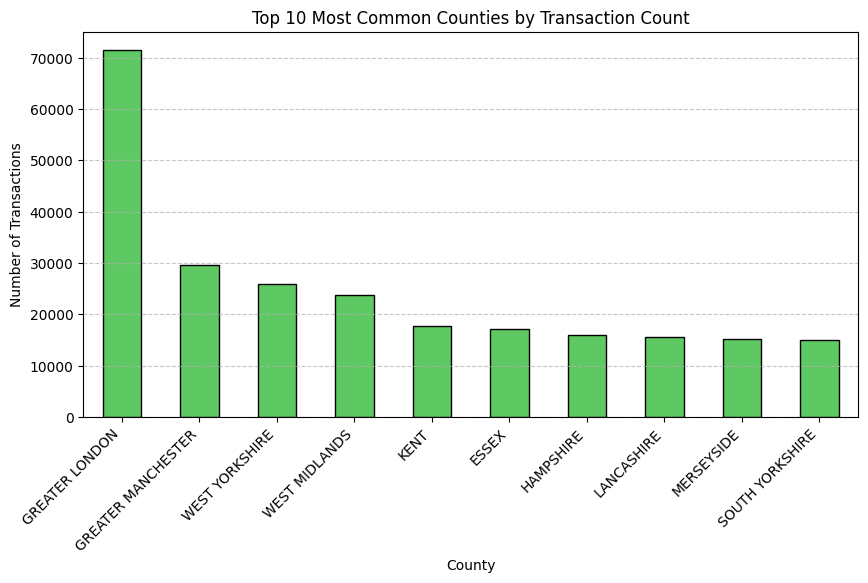

In [21]:
# Get the 10 counties with the most transactions
top_counties = property_prices['County'].value_counts().head(10)

# Plot bar chart of the top 10 counties
plt.figure(figsize=(10, 5))
top_counties.plot(kind="bar", color="#5ec962", edgecolor="black")
plt.xlabel("County")
plt.ylabel("Number of Transactions")
plt.title("Top 10 Most Common Counties by Transaction Count")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show() 

Among the most active counties are **Greater London**, **Greater Manchester**, **West Yorkshire**, and the **West Midlands** — each home to some of the UK’s largest metropolitan areas, including London, Manchester, Leeds, and Birmingham respectively. Notably, Greater London saw more than twice as many transactions as Greater Manchester, accounting for **over 11% of all transactions nationwide**. This highlights its dominance in the UK housing market.

### Temporal Trends in Property Transactions

Transaction dates offer another valuable perspective on property market behaviour. To observe seasonal patterns, the date data has been aggregated into monthly intervals and visualised as a time series.

/var/folders/8y/tt63y6sx2wv_8t3qwxp4gwwm0000gn/T/ipykernel_68803/2544902857.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  property_prices["Month"] = property_prices['Date_of_sale'].dt.to_period("M")


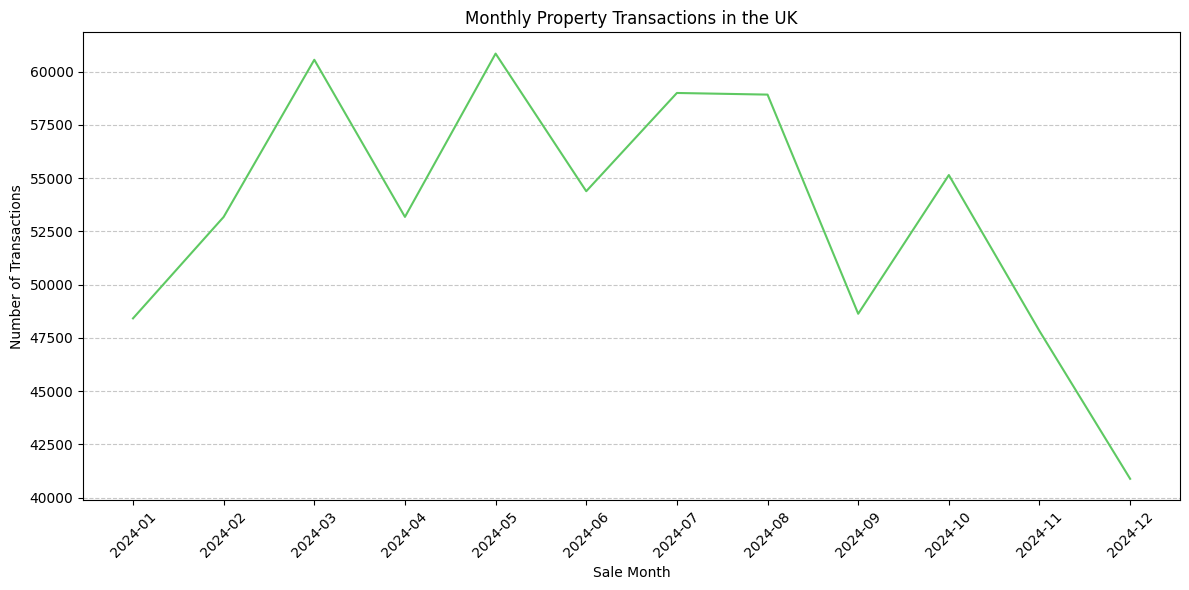

In [22]:
# Create a Year-Month column from the sale date
property_prices["Month"] = property_prices['Date_of_sale'].dt.to_period("M")

# Count number of sales per month
price_trend = property_prices["Month"].value_counts().sort_index()

# Plot the number of property sales over time
plt.figure(figsize=(12, 6))
plt.plot(price_trend.index.astype(str), price_trend, linestyle="-", color="#5ec962")
plt.xlabel("Sale Month")
plt.ylabel("Number of Transactions")
plt.title("Monthly Property Transactions in the UK")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

In [23]:
summer_months = pd.DataFrame(price_trend).reset_index()
summer_months['Month Aggregate'] = (summer_months['Month'] <= '2024-08') & (summer_months['Month'] >= '2024-03')
summer_months['Month Aggregate'] = summer_months['Month Aggregate'].apply(lambda x : 'Warmer Months' if x else 'Colder Months')
round(pd.DataFrame(summer_months.groupby('Month Aggregate')['count'].mean()).rename(columns={'count' : 'Average number of transactions'}))

,Average number of transactions
Month Aggregate,
Colder Months,49012.0
Warmer Months,57816.0


The time series plot shows that property purchases peak between **March and August**, aligning with the spring and summer months. On average, **18% more properties** are sold in warmer months compared to the number of properties sold in winter months. This seasonal trend suggests that buyers are more active during warmer periods, possibly due to better weather, longer daylight hours, and alignment with school or work transitions.

To explore whether this seasonal behaviour varies by region, the following analysis compares trends in **popular counties** (as identified earlier) against less active areas.

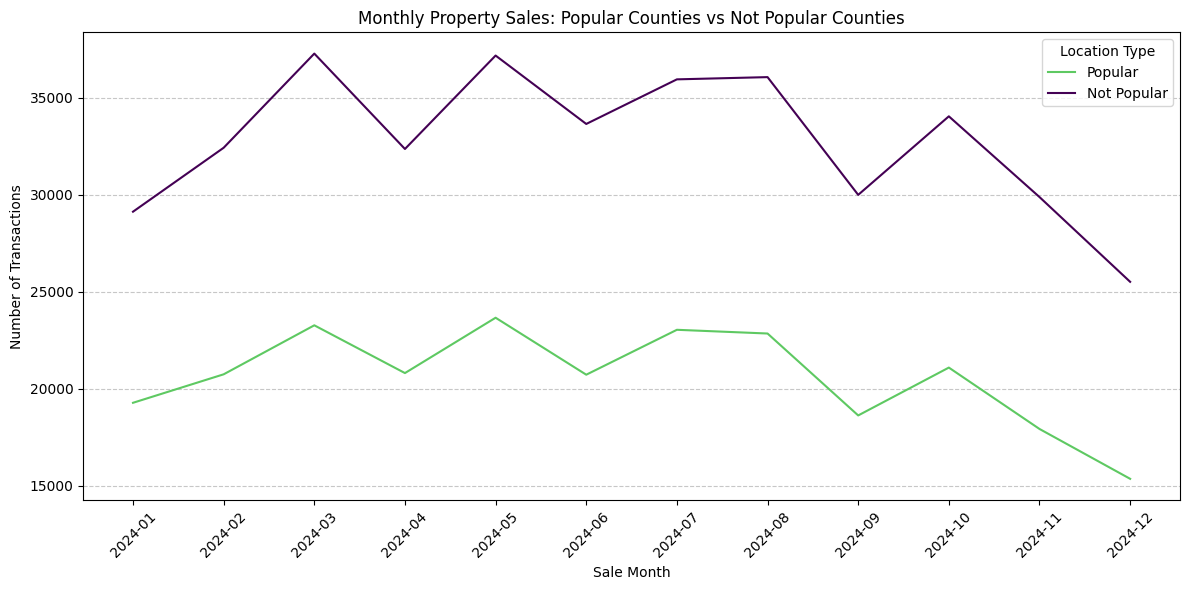

In [24]:
# Copy the DataFrame to avoid modifying the original
temp = property_prices.copy()

# Get the 10 most common counties
pop_counties = temp['County'].value_counts().head(10).index

# Create a new column indicating if a property is in a popular county
temp['Popular Local'] = temp['County'].apply(lambda x: x in pop_counties)

# Group by Month and whether the property is in a popular county
type_trend = temp.groupby(["Month", "Popular Local"]).size().unstack(fill_value=0)

# Plot property sales over time for popular vs. non-popular counties
plt.figure(figsize=(12, 6))
for column, colour in zip([True, False], ["#5ec962", "#440154"]):
    plt.plot(type_trend.index.astype(str), type_trend[column], label="Popular" if column else "Not Popular", color=colour)

# Add labels and styling
plt.xlabel("Sale Month")
plt.ylabel("Number of Transactions")
plt.title("Monthly Property Sales: Popular Counties vs Not Popular Counties")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend(title="Location Type")
plt.tight_layout()
plt.show()

The results show that seasonality in transaction volume is **consistent across both popular and less populated regions**. Regardless of location, property sales tend to rise in the spring and summer and decline during the colder months. This implies that **seasonal influences on property buying behaviour are widespread** and not limited to urban or high-demand areas.

### Understanding Property Price Distribution

As previously observed, the mean price is noticeably higher than the median, indicating a **positively skewed distribution**. This suggests that the dataset contains a larger number of lower-value transactions, with fewer high-priced outliers pulling the average upward. To better visualise this skewness, a log transformation is applied to the price variable.

/var/folders/8y/tt63y6sx2wv_8t3qwxp4gwwm0000gn/T/ipykernel_68803/1169439920.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  property_prices['Log Price'] = np.log10(property_prices["Price"])


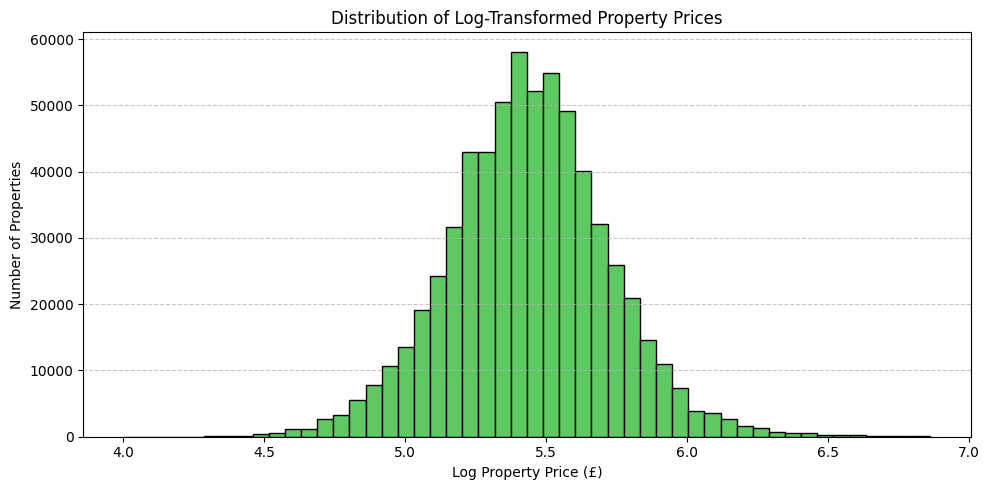

In [25]:
# Create a new column with log-transformed property prices (base 10)
property_prices['Log Price'] = np.log10(property_prices["Price"])

# Plot histogram of log-transformed prices
plt.figure(figsize=(10, 5))
plt.hist(property_prices["Log Price"], bins=50, edgecolor="black", color="#5ec962")
plt.xlabel("Log Property Price (£)")
plt.ylabel("Number of Properties")
plt.title("Distribution of Log-Transformed Property Prices")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

Applying a log transformation to the price variable results in a more symmetric distribution, making it easier to visualise and interpret. This transformation compresses extreme values and highlights patterns in the mid-range more clearly. As a result, **log price** is used in many parts of the analysis to reduce the impact of high-value outliers.

Because the data remains skewed even after filtering and transformation, the **median** is a more appropriate measure of central tendency than the mean. It better reflects typical values while remaining robust to distortion from unusually high or low prices.

The following visualisations explore how physical property characteristics, such as type and age, relate to log-transformed property prices.

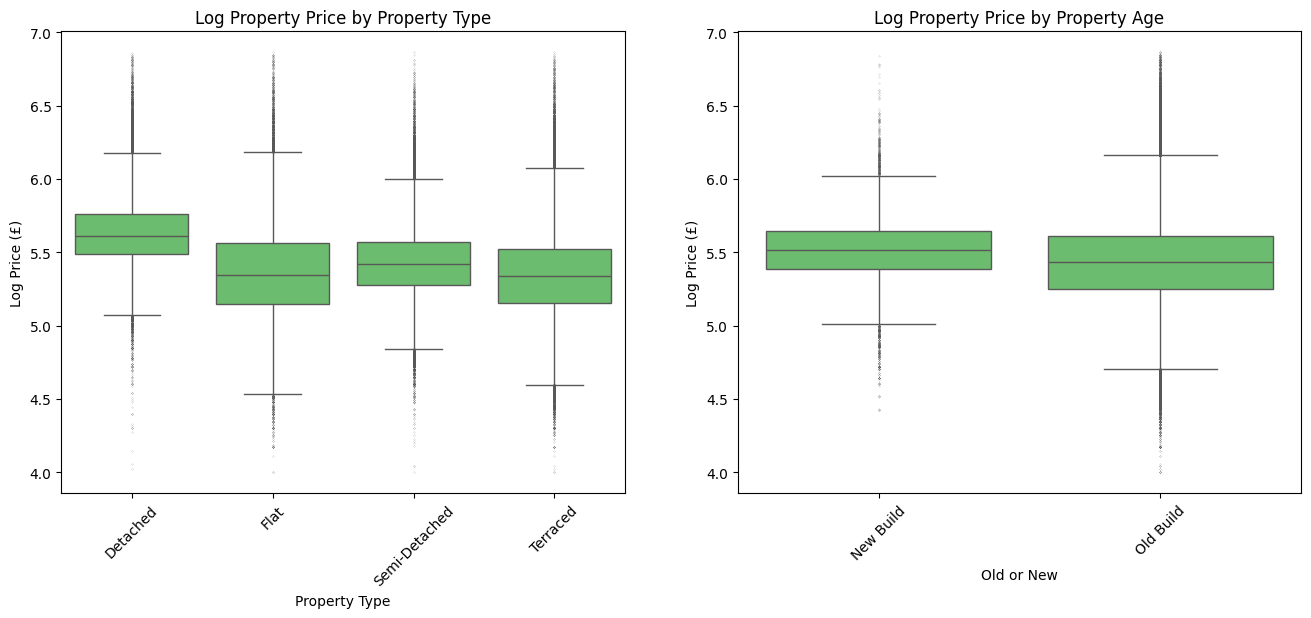

In [26]:
# Create side-by-side boxplots to compare log-transformed property prices
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot( #Plot boxplot exploring the property type
    data=property_prices,
    x="Property_type",
    y="Log Price",
    flierprops={'markersize': 0.1}, #Adjust the size of the outlier points
    color='#5ec962',
    ax=axes[0] #I want this to appear in the first subplot space
)
axes[0].set_title("Log Property Price by Property Type")
axes[0].set_xlabel("Property Type")
axes[0].set_ylabel("Log Price (£)")
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot( #Plot boxplot exploring the property age
    data=property_prices,
    x="Old/new",
    y="Log Price",
    flierprops={'markersize': 0.1}, #Adjust the size of the outlier points
    color='#5ec962',
    ax=axes[1] #I want this to appear in the second subplot space
)
axes[1].set_title("Log Property Price by Property Age")
axes[1].set_xlabel("Old or New")
axes[1].set_ylabel("Log Price (£)")
axes[1].tick_params(axis='x', rotation=45)

plt.show()

A box plot summarises key aspects of a distribution: the median, interquartile range (IQR), and outliers beyond the 25th and 75th percentiles. The left-hand plot shows the distribution of log-transformed prices by property type. **Detached properties** clearly exhibit a higher median price than other categories, indicating that they are generally the most expensive.

The right-hand plot compares prices for **old vs. new** properties. Both categories show similar median prices, suggesting that property age does not have a major effect on typical sale values. However, older properties exhibit greater spread and variability, which may reflect wider differences in quality, location, or condition.

In [27]:
# Function to calculate interquartile range, taking a series and returning a float
def IQR(series : pd.Series) -> float:
    return series.quantile(0.75) - series.quantile(0.25)

# Function to summarise log-transformed prices by a given attribute
def logged_price_summary_table(attribute : str) -> pd.DataFrame:
    # Group by the attribute and calculate summary stats on Log Price
    summary_table = property_prices.groupby(attribute, observed=False)['Log Price'].agg(['median', 'count', IQR]).rename(columns={
        'median': 'Log Median',
        'count': 'Count',
        'IQR': 'Log IQR'
    })

    # Convert log median back to actual price
    summary_table['Median (£)'] = 10**summary_table['Log Median']

    # Add proportion column
    summary_table['Proportion (%)'] = round(summary_table['Count'] / summary_table['Count'].sum(), 4) * 100

    # Reorder columns
    return summary_table[['Log Median', 'Log IQR', 'Median (£)', 'Count', 'Proportion (%)']]

# Display summary tables
print('Property type table')
print(logged_price_summary_table('Property_type'))
print()
print('Property age table')
print(logged_price_summary_table('Old/new'))


Property type table
               Log Median   Log IQR  Median (£)   Count  Proportion (%)
Property_type                                                          
Detached         5.612784  0.277707    410000.0  146119           22.80
Flat             5.347330  0.413074    222500.0  112309           17.52
Semi-Detached    5.418301  0.289448    262000.0  186300           29.07
Terraced         5.342423  0.370156    220000.0  196242           30.62

Property age table
           Log Median   Log IQR  Median (£)   Count  Proportion (%)
Old/new                                                            
New Build    5.518507  0.254287    329995.0   21451            3.35
Old Build    5.432969  0.364477    271000.0  619519           96.65


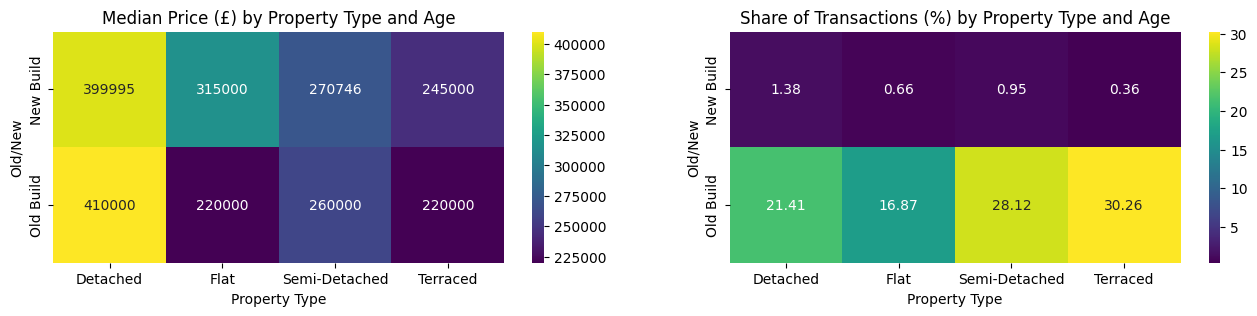

In [28]:
# Create pivot table showing the median price by property type and whether it's old/new
median_price_pivot = property_prices.pivot_table(
    index="Old/new", 
    columns="Property_type", 
    values="Price", 
    aggfunc="median",
    observed=True
)

# Create pivot table show the transaction count by property type and old/new
count_price_pivot = property_prices.pivot_table(
    index="Old/new", 
    columns="Property_type", 
    values="Price", 
    aggfunc="size",
    observed=True
)

# Convert counts to proportions (% of total)
count_price_pivot = count_price_pivot * 100 / count_price_pivot.sum().sum()

# Plot heatmaps
fig, axes = plt.subplots(1, 2, figsize=(16, 3))

# Heatmap of median prices
sns.heatmap(median_price_pivot, annot=True, fmt=".0f", cmap="viridis", ax=axes[0])
axes[0].set_title("Median Price (£) by Property Type and Age")
axes[0].set_xlabel("Property Type")
axes[0].set_ylabel("Old/New")

# Heatmap of percentage of transactions
sns.heatmap(count_price_pivot, annot=True, fmt=".2f", cmap="viridis", ax=axes[1])
axes[1].set_title("Share of Transactions (%) by Property Type and Age")
axes[1].set_xlabel("Property Type")
axes[1].set_ylabel("Old/New")

plt.show()


As observed earlier, **detached properties tend to command higher prices** across the dataset. In the left-hand heatmap below, we examine how this trend interacts with property age. Interestingly, while age appears to have little effect on most property types, **new build flats** exhibit noticeably higher prices than their older counterparts. This may reflect modern developments in high-value urban areas or premium finishes in newer apartment complexes.

However, it's important to interpret this result cautiously - **new build flats make up just 0.65% of the dataset**. Such a small sample size increases the risk that the trend is due to random variation. A larger sample would be required to confirm whether this pattern is representative of the broader market.

Whilst it's important to understand what sort of properties are available on the market and what sort of properties are investing in, it is equally important to understand **the nature of the transaction**. Specifically, we can see if different tenure types are more frequent with different property types.

/var/folders/8y/tt63y6sx2wv_8t3qwxp4gwwm0000gn/T/ipykernel_68803/1077358098.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  property_type_tenure_pivot_table = property_prices.reset_index().pivot_table(


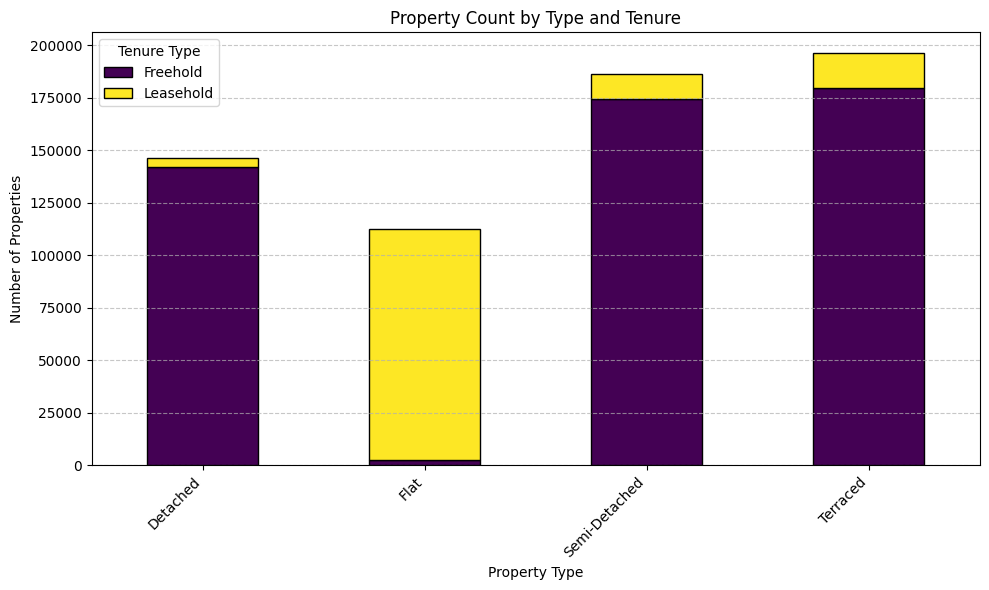

In [29]:
property_type_tenure_pivot_table = property_prices.reset_index().pivot_table(
    index='Property_type',
    columns='Tenure',
    values='Identifier',
    aggfunc='count'
)

# Plot the stacked bar chart
property_type_tenure_pivot_table.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='viridis',
    edgecolor='black'
)

# Axis and title formatting
plt.xlabel("Property Type")
plt.ylabel("Number of Properties")
plt.title("Property Count by Type and Tenure")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Tenure Type")
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

From the above **stacked bar chart**, you can see that most of the purchases of detached, semi-detached and terraced properties are **freehold**. This means that the individual(s) purchasing the property are also purchasing the land it sits on. Conversely, **only 2.3% of flats** are freehold. Instead, the majority of them are **leasehold**, meaning that the majority of transactions, someone else owns the land it sits on. This makes sense as flats are usually in buildings with other flats.

From the below table, freehold properties have a higher median price (£290,000) than leasehold properties (£215,000). The lower price of leaseholds can be attributed to the fact that the purchase is not inclusive on the land.

In [30]:
logged_price_summary_table("Tenure")

,Log Median,Log IQR,Median (£),Count,Proportion (%)
Tenure,,,,,
Freehold,5.462398,0.343434,290000.0,498114,77.71
Leasehold,5.332438,0.385351,215000.0,142856,22.29


### Regional Price Disparities

Windsor and Maidenhead emerges as the most expensive county, with an average property price nearing £1 million. Other high-ranking counties include Greater London, Surrey, Buckinghamshire, and Hertfordshire. Notably, Greater London stands out as both one of the most active and one of the most expensive counties, indicating that high prices do not appear to deter buyer demand.

In contrast, the least expensive counties — such as County Durham and Blackpool — have average prices below £150,000. This significant regional disparity suggests that **location is a major driver of property value**. Initial observations indicate that higher-priced counties are predominantly located in or around London, whereas lower-priced areas tend to cluster further north.

To explore this spatial pattern in more depth, postcode data will be converted into latitude and longitude coordinates using the ONS Postcode Directory. This enables us to move from categorical to numeric location data for more sophisticated geospatial analysis.


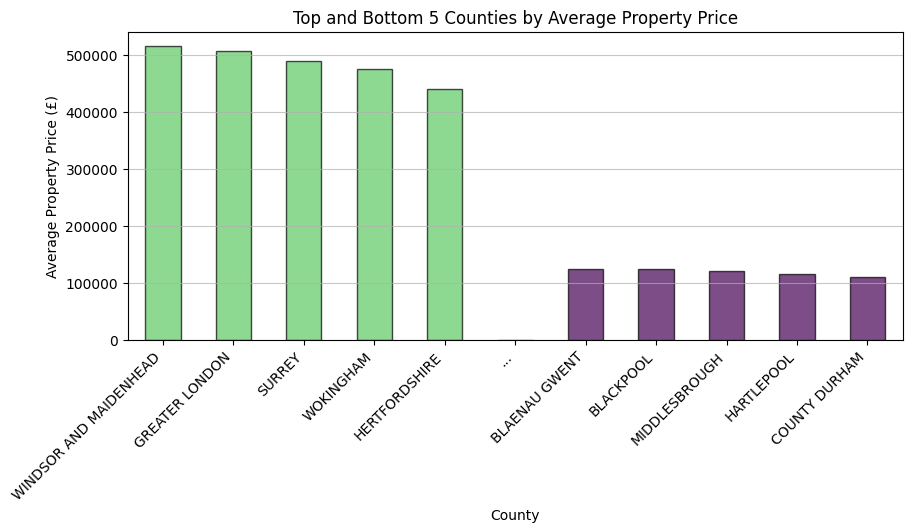

In [31]:
# Calculate average property price by county
top_counties = property_prices.groupby('County')['Price'].median().sort_values(ascending=False)

# Select the top and bottom 5 counties
top_5_counties = top_counties.head(5)
bottom_5_counties = top_counties.tail(5)

# Combine with a separator in the middle
top_bottom_counties = pd.concat([top_5_counties, pd.Series({'...' : 0}), bottom_5_counties])

# Define bar colors. green for top 5, purple for bottom 5, grey for separator, which is arbitrary
colors = ['#5ec962'] * 5 + ['grey'] + ['#440154'] * 5

# Plot the average prices
plt.figure(figsize=(10, 4))
top_bottom_counties.plot(kind="bar", color=colors, edgecolor="black", alpha=0.7)
plt.xlabel("County")
plt.ylabel("Average Property Price (£)")
plt.title("Top and Bottom 5 Counties by Average Property Price")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.7)
plt.show()


In [32]:
# Read postcode lookup data, keeping only postcode, latitude, and longitude
postcode_to_lat_long = pd.read_csv('ONSPD_FEB_2024_UK.csv')[['pcd', 'lat', 'long']]

# Remove spaces from postcodes and convert to uppercase in property data to ensure the same format
property_prices['Postcode'] = property_prices['Postcode'].apply(lambda x: str(x).replace(' ', '').upper())

# Remove spaces from postcodes and convert to uppercase in the lookup table to ensure the same format
postcode_to_lat_long['pcd'] = postcode_to_lat_long['pcd'].apply(lambda x: str(x).replace(' ', '').upper())

# Display the postcode-to-coordinates mapping
postcode_to_lat_long

/var/folders/8y/tt63y6sx2wv_8t3qwxp4gwwm0000gn/T/ipykernel_68803/3309324901.py:2: DtypeWarning: Columns (18,31,40,45,50,51,52) have mixed types. Specify dtype option on import or set low_memory=False.
  postcode_to_lat_long = pd.read_csv('ONSPD_FEB_2024_UK.csv')[['pcd', 'lat', 'long']]
/var/folders/8y/tt63y6sx2wv_8t3qwxp4gwwm0000gn/T/ipykernel_68803/3309324901.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  property_prices['Postcode'] = property_prices['Postcode'].apply(lambda x: str(x).replace(' ', '').upper())


,pcd,lat,long
0,AB10AA,57.101474,-2.242851
1,AB10AB,57.102554,-2.246308
2,AB10AD,57.100556,-2.248342
3,AB10AE,57.084444,-2.255708
4,AB10AF,57.096656,-2.258102
...,...,...,...
2700772,ZE39JW,59.873651,-1.305697
2700773,ZE39JX,59.875286,-1.307502
2700774,ZE39JY,59.891572,-1.313847
2700775,ZE39JZ,59.892392,-1.310899


While most postcodes in the property dataset successfully match with coordinates in the ONS Postcode Directory, a small proportion do not. Specifically, 600 unique postcodes in the property data (approximately **0.7%**) are missing from the postcode-to-coordinate dataset. These unmatched records will be excluded to ensure clean and accurate spatial analysis.

In [33]:
#a set is an object which can't take duplicates and when subtracting two sets, we get whats in the former but not the prior
len(set(property_prices['Postcode']) - set(postcode_to_lat_long['pcd']))

600

To maintain data quality, properties with postcodes that cannot be mapped to geographic coordinates are excluded from the analysis. A new DataFrame is created by merging the main dataset with the coordinate data, allowing for property-level spatial calculations and visualisations.

In [34]:
# Merge property data with postcode coordinates using postcode as the key
# This adds latitude and longitude to each property based on its postcode
property_prices_LONG_LAT_raw = property_prices.merge(
    postcode_to_lat_long,
    left_on='Postcode',
    right_on='pcd',
    how='inner'
)

### Investigating Distance from London

With geospatial coordinates now available, we can explore whether proximity to London influences property prices. To reduce noise and better capture spatial trends, the data is aggregated at the **town/city level**. This approach strikes a balance between granularity and interpretability, offering more detail than county-level aggregation while still providing consistent regional patterns.

Each town or city is assigned a coordinate based on the **median latitude and longitude** of all properties located within it. Property prices are summarised in the same way using the average sale price.

Before we can aggregate the data by Town/city, we need to assure that each unique value of Town/city points to the same urban area. This can be done by exploiting the structure of the postcode data. The suffix of letters in a postcode string denotes an area. This is a unique code, distinct to different areas of England and Wales. I extracted this data using regular expression, or Regex.

In [35]:
property_prices_LONG_LAT_raw['Area'] = property_prices_LONG_LAT_raw['Postcode'].str.extract(r'^([A-Z]{1,2})')

area_by_town = property_prices_LONG_LAT_raw.groupby('Town/city')[['Area']].agg([set, 'nunique'])['Area']
area_by_town[area_by_town['nunique'] > 1]

,set,nunique
Town/city,,
ASHFORD,"{TN, TW}",2
BIRKENHEAD,"{CH, L}",2
CHESTER,"{CH, CW}",2
DONCASTER,"{DN, S}",2
DUDLEY,"{B, DY}",2
ENFIELD,"{EN, N}",2
GILLINGHAM,"{SP, ME}",2
LONDON,"{W, N, NW, DA, IG, SE, SW, E, WC, EC}",10
NEWPORT,"{TF, PO, SA, NP}",4


Above is a dataframe of all instances where a town/city saw more than one postcode suffix. After manually parsing through the above table, seven of these Town/city values can be split up as they're not referring to the same area. Below is a list of these confused values:

- **ASHFORD**. 
    - TW = West London/Surrey, TN = Kent.
- **GILLINGHAM**.	
    - ME = Kent, SP = Dorset/Wiltshire.
- **RICHMOND**. 
    - TW = London/Surrey, DL = North Yorkshire.
- **ST IVES**. 
    - TR = Cornwall, PE = Cambridgeshire.
- **TALYBONT**. 
    - LL = North Wales, SY = Mid Wales/Shropshire.
- **WHITCHURCH**. 
    - SY = Shropshire, RG = Reading area.
- **NEWPORT**. 
    - NP = South Wales, SA = Swansea, PO = Isle of Wight, TF = Telford. These are actually **four different Newports!**

The remaining values are instances where the town/city falls on one of more postcode boundaries.



In [36]:
property_prices_LONG_LAT_raw['Town/city'] = property_prices_LONG_LAT_raw.apply(lambda x : x['Town/city'] + ', ' + x['Area'] if x['Town/city'] in ['ASHFORD', 'GILLINGHAM', 'RICHMOND', 'ST IVES', 'TALYBONT', 'WHITCHURCH', 'NEWPORT'] else x['Town/city'], axis=1)

Above overwrites the name of Towns/cities that are observed in more than 1, completely different part of the country by concatenating the postcode area code. Now we can safely aggregate by Town/city.

In [37]:
# Group by town/city and calculate the average latitude, longitude, and property price
property_prices_LONG_LAT = property_prices_LONG_LAT_raw.groupby(['Town/city'])[['lat', 'long', 'Price']].median()

# View the resulting table with one row per town/city
property_prices_LONG_LAT

,lat,long,Price
Town/city,,,
ABBOTS LANGLEY,51.702149,-0.414527,431000.0
ABERAERON,52.239848,-4.262561,272750.0
ABERDARE,51.713619,-3.446954,136000.0
ABERDOVEY,52.546980,-4.046952,260000.0
ABERGAVENNY,51.825092,-3.016152,325000.0
...,...,...,...
YATELEY,51.337768,-0.834890,470000.0
YELVERTON,50.494255,-4.099310,278000.0
YEOVIL,50.949255,-2.645594,240000.0


To measure how far each town or city is from London, we begin by selecting a fixed reference point — the average latitude and longitude of properties located in **London**. Using the geopy library, we then calculate the **geodesic distance** between each town’s coordinates and London’s coordinates. This allows us to analyse how price varies with distance from the capital.


In [38]:
# Get latitude and longitude for London
london_lat = property_prices_LONG_LAT.loc['LONDON']['lat']
london_long = property_prices_LONG_LAT.loc['LONDON']['long']

# Calculate distance from London for each town/city
property_prices_LONG_LAT['Distance_from_london'] = property_prices_LONG_LAT.apply(
    lambda x: geodesic((x['lat'], x['long']), (london_lat, london_long)).kilometers,
    axis=1 #this ensures we are working with the rows of the DF instead of the columns
)

# Sort towns/cities by distance from London
property_prices_LONG_LAT.sort_values(by='Distance_from_london')

,lat,long,Price,Distance_from_london
Town/city,,,,
LONDON,51.502897,-0.114607,555000.0,0.000000
MITCHAM,51.405306,-0.159216,410000.0,11.291767
THORNTON HEATH,51.399699,-0.103683,380000.0,11.506575
BECKENHAM,51.406276,-0.030566,530000.0,12.234416
"RICHMOND, TW",51.463329,-0.293103,720000.0,13.157719
...,...,...,...,...
BELFORD,55.597268,-1.828602,270000.0,469.597892
ISLES OF SCILLY,49.914391,-6.310226,410000.0,471.776021
MINDRUM,55.592647,-2.174741,332250.0,475.161312


The figure below consists of two visualisations. On the left is a scatter plot showing the relationship between each town or city's distance from London and the **log-transformed average property price**. On the right is a bar chart that groups towns into **discrete distance bands** (in 50 km intervals) and displays the corresponding **average price** (in £, unlogged). Together, these plots provide a visual overview of how property prices vary with distance from the capital.

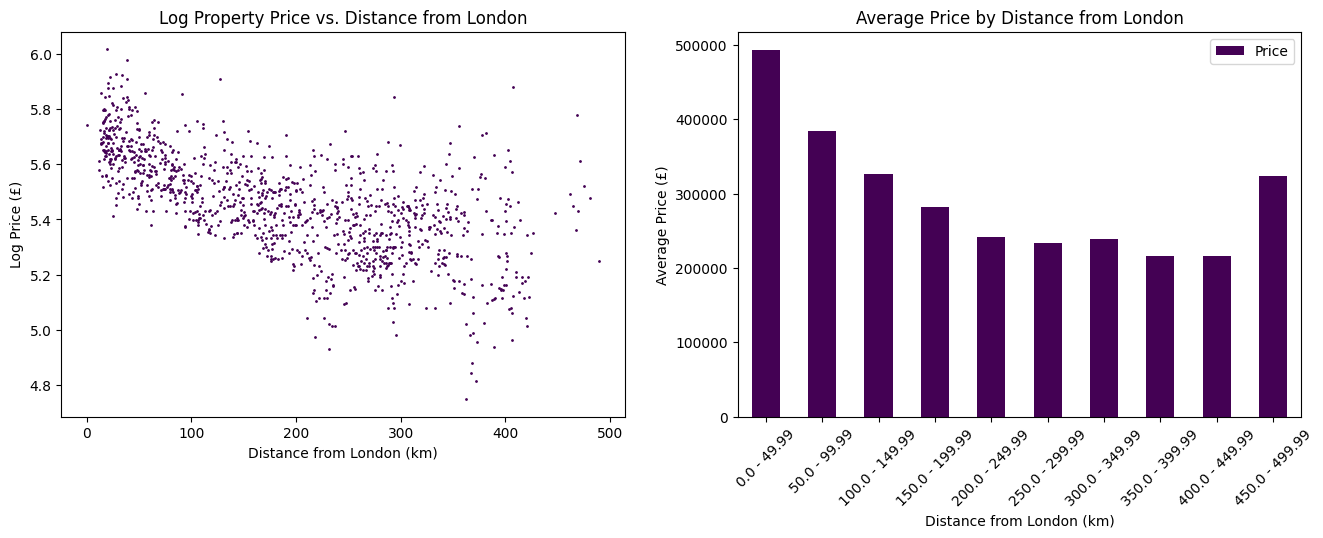

In [39]:
# Function to convert a value into a category bin string (e.g., "0 - 49.99")
def create_discrete_categories(value, class_size):
    lb = value // class_size
    return f"{float(lb * class_size)} - {float((lb + 1) * class_size - 0.01)}"

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Add a log-transformed price column
property_prices_LONG_LAT['Log Price'] = property_prices_LONG_LAT['Price'].apply(math.log10)

# Scatter plot: Log price vs. distance from London
property_prices_LONG_LAT.plot(
    x='Distance_from_london',
    y='Log Price',
    kind='scatter',
    s=1,
    color='#440154',
    ax=axes[0]
)
axes[0].set_title("Log Property Price vs. Distance from London")
axes[0].set_xlabel("Distance from London (km)")
axes[0].set_ylabel("Log Price (£)")

# Create distance categories in 50 km bins
property_prices_LONG_LAT['Distance Category'] = property_prices_LONG_LAT['Distance_from_london'].apply(
    lambda x: create_discrete_categories(x, 50)
)

# Group by distance category and calculate average price
property_prices_LONG_LAT_discrete = property_prices_LONG_LAT.groupby('Distance Category', as_index=False)[['Price']].mean()

# Add a numeric index to allow sorting
property_prices_LONG_LAT_discrete['Distance Category Index'] = property_prices_LONG_LAT_discrete['Distance Category'].apply(
    lambda x: float(x.split(' ')[0])
)
property_prices_LONG_LAT_discrete = property_prices_LONG_LAT_discrete.sort_values(by='Distance Category Index')

# Bar plot: average price by distance category
property_prices_LONG_LAT_discrete.plot(
    x='Distance Category',
    y='Price',
    kind='bar',
    color='#440154',
    ax=axes[1]
)
axes[1].set_title("Average Price by Distance from London")
axes[1].set_xlabel("Distance from London (km)")
axes[1].set_ylabel("Average Price (£)")
axes[1].tick_params(axis='x', rotation=45)

plt.show()

While the correlation is relatively weak, the scatter plot reveals a **general negative trend**: as distance from London increases, property prices tend to decline. This relationship appears roughly **log-linear**, suggesting that price decreases at a diminishing rate as distance grows. The bar chart reinforces this trend, although there is an unexpected peak in average price between **450–500 km**. To understand this anomaly, the towns that fall into this distance band are examined in more detail.

In [40]:
# Filter towns/cities that are 450 km or more from London and sort them by average price
property_prices_LONG_LAT[property_prices_LONG_LAT['Distance_from_london'] >= 450].sort_values(by='Price')

,lat,long,Price,Distance_from_london,Log Price,Distance Category
Town/city,,,,,,
BERWICK-UPON-TWEED,55.758109,-2.009634,177900.0,489.859059,5.250176,450.0 - 499.99
WOOLER,55.549113,-2.015623,231000.0,467.595342,5.363612,450.0 - 499.99
BELFORD,55.597268,-1.828602,270000.0,469.597892,5.431364,450.0 - 499.99
SEAHOUSES,55.579498,-1.653238,280000.0,465.004262,5.447158,450.0 - 499.99
CORNHILL-ON-TWEED,55.641945,-2.201066,300000.0,480.894542,5.477121,450.0 - 499.99
CHATHILL,55.554921,-1.633343,309500.0,462.053136,5.490661,450.0 - 499.99
MINDRUM,55.592647,-2.174741,332250.0,475.161312,5.521465,450.0 - 499.99
ISLES OF SCILLY,49.914391,-6.310226,410000.0,471.776021,5.612784,450.0 - 499.99
BAMBURGH,55.605038,-1.722091,600000.0,468.785024,5.778151,450.0 - 499.99


The unusually high prices observed in the 450–500 km range can be attributed to two outliers: **Bamburgh**, a coastal town famed for its historic castle, and the **Isles of Scilly**, a remote island group off the coast of Cornwall. These locations are known for their scenic and exclusive real estate, which skews the average within this otherwise sparsely populated distance band. Despite these outliers, the broader trend still holds — **property prices tend to be lower the farther a location is from London**.

To illustrate this pattern more clearly, a cartogram-style scatter map is plotted below. Each point represents a property transaction, and colour intensity reflects the **log-transformed price**.

<function matplotlib.pyplot.show(close=None, block=None)>

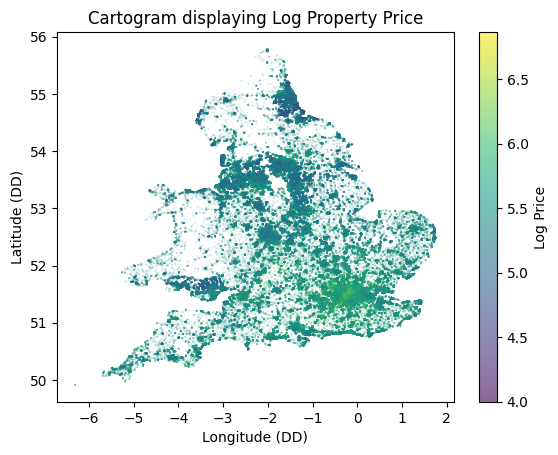

In [41]:
# Plot a cartogram-style scatter map with color based on log-transformed price
property_prices_LONG_LAT_raw.plot(
    x='long',
    y='lat',
    kind='scatter',
    c='Log Price',       
    colormap='viridis',   
    s=0.005,                 # Tiny point size for density effect
    alpha=0.6              
)

plt.xlabel("Longitude (DD)")
plt.ylabel("Latitude (DD)")
plt.title("Cartogram displaying Log Property Price")

plt.show


The cartogram reveals a clear **geographic gradient in property prices**, with higher prices clustered in and around **London and the South East**. Conversely, lower prices dominate much of the **North and West**. This supports the earlier observation that proximity to London is associated with higher prices.

Interestingly, there are scattered clusters of high-value transactions in areas like the **North West** and **South West**, suggesting that proximity to major urban centres might also play a role in determining price. This raises a new question: **do properties become cheaper as they move away from desirable towns and cities**, regardless of distance from London?


To investigate this, I identify the **five most commonly occurring towns/cities** in the dataset based on transaction count. I consider these areas "desirable" as the large amount of property transactions in this area either indicate that individuals actively want to move to/remain in these towns/cities or there has been a dramatic increase of available properties in these areas due to urban development. For each location in the dataset, I will compute the **distance to each of these five major towns**, and record the **shortest distance** to any of them. This allows me to measure how far a town is from a high-activity urban centre, and to assess whether **proximity to desirable cities** influences property values in the same way proximity to London does.

In [42]:
# Get the 5 most common towns/cities in the dataset
pop_cities = property_prices['Town/city'].value_counts().head(5).index

# Get average lat/long for each of those popular cities
city_locations = property_prices_LONG_LAT.loc[pop_cities]

# Copy the full table of towns for distance calculations
pop_cities_analysis = property_prices_LONG_LAT.copy()

# Track names of the distance columns
popular_TC_col_names = []

# Calculate distance from each town to each of the top 5 cities
for city in city_locations.index:
    curr_city_long = float(city_locations.loc[city]['long'])
    curr_city_lat = float(city_locations.loc[city]['lat'])

    # Add distance column for current city
    col_name = f'Distance from {city}'
    pop_cities_analysis[col_name] = pop_cities_analysis.apply(
        lambda x: geodesic((x['lat'], x['long']), (curr_city_lat, curr_city_long)).kilometers,
        axis=1
    )
    popular_TC_col_names.append(col_name)

# Add column with the minimum distance to any of the top 5 cities
pop_cities_analysis['Min Distance to Top 5 Cities'] = pop_cities_analysis[popular_TC_col_names].min(axis=1)

Below is a corrleation analysis, investigating the relationship between the average price of a town/city and the different distance metrics. These numbers are always between -1 and 1, with the former implying a perfect **negative correlation** and the latter implying a perfect **postive correlation**. In this context, -1 would imply that as the town/city distance from each location increases, the average price decreases, whilst the opposite is true if the correlation value is equal to 1.

In [43]:
# Get correlation between distance from each top city (and min distance) and average property price
pop_cities_analysis[popular_TC_col_names + ['Min Distance to Top 5 Cities', 'Price']].corr()['Price']

Distance from LONDON           -0.632107
Distance from MANCHESTER        0.462738
Distance from BRISTOL          -0.288468
Distance from NOTTINGHAM        0.129768
Distance from BIRMINGHAM       -0.012619
Min Distance to Top 5 Cities   -0.296120
Price                           1.000000
Name: Price, dtype: float64

Notably, the correlation between property price and distance from London is approximately –0.57, supporting the earlier observation that property prices tend to decrease as distance from the capital increases. In contrast, the correlation between distance from Manchester and price is +0.42, indicating that properties located farther from Manchester tend to be more expensive. This suggests a broader geographic pattern — a north–south divide — where southern proximity, particularly to London, is associated with higher property values.

Additionally, the correlation between minimum distance to any of the top five cities and price is slightly negative. While weak, this relationship implies that more remote or rural areas may sometimes command higher prices than urban centres — potentially reflecting demand for exclusivity, space, or scenic value. This idea is further supported by the statistics that follow.

In [44]:
# Create a flag for towns that are within 30 km of one of the top 5 most popular cities
pop_cities_analysis['Near Popular City Flag'] = pop_cities_analysis['Min Distance to Top 5 Cities'] <= 30

These are the mean property prices for two distinct groups: properties located within a 30-kilometre radius of a major city, and those located beyond that range. The results suggest that, on average, properties situated more than 30 kilometres from a major city are cheaper.

In [45]:
property_prices_LONG_LAT_pop_cities_raw = property_prices_LONG_LAT_raw.merge(pop_cities_analysis[['Min Distance to Top 5 Cities', 'Near Popular City Flag']], on='Town/city', how='left')

/var/folders/8y/tt63y6sx2wv_8t3qwxp4gwwm0000gn/T/ipykernel_68803/3753034145.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  property_prices_LONG_LAT_pop_cities = property_prices_LONG_LAT_pop_cities_raw.pivot_table(index='Property_type', columns='Near Popular City Flag', values='Price', aggfunc='median')


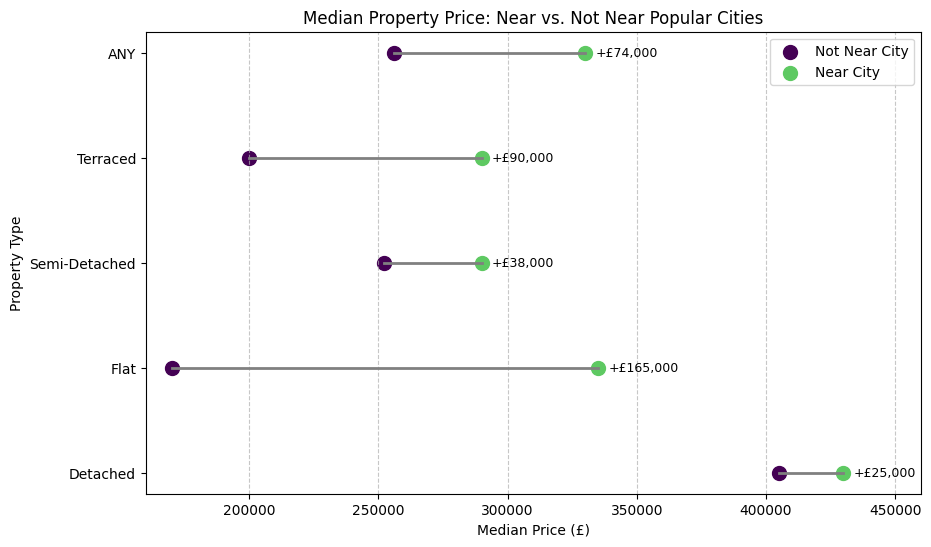

In [46]:
#Create a pivot table outlining the average price per property type aggregated by if they are near a major city or not.
property_prices_LONG_LAT_pop_cities = property_prices_LONG_LAT_pop_cities_raw.pivot_table(index='Property_type', columns='Near Popular City Flag', values='Price', aggfunc='median')
#For clear visualisation, add 'ANY' which represents the global statistics
subtable = property_prices_LONG_LAT_pop_cities_raw.pivot_table(columns='Near Popular City Flag', values='Price', aggfunc='median')
subtable.index = ['ANY']

#Combine the tables to create long pivot table.
property_prices_LONG_LAT_pop_cities = pd.concat([property_prices_LONG_LAT_pop_cities,subtable])

#Difference is the price difference between urban and rural properties.
property_prices_LONG_LAT_pop_cities['Difference'] = property_prices_LONG_LAT_pop_cities[True] - property_prices_LONG_LAT_pop_cities[False]

plt.figure(figsize=(10, 6))

for idx in property_prices_LONG_LAT_pop_cities.index:
    # Left circle (False)
    plt.scatter(property_prices_LONG_LAT_pop_cities.loc[idx, False], idx, color='#440154', s=100, label='Not Near City' if idx == property_prices_LONG_LAT_pop_cities.index[0] else "")
    # Right circle (True)
    plt.scatter(property_prices_LONG_LAT_pop_cities.loc[idx, True], idx, color='#5ec962', s=100, label='Near City' if idx == property_prices_LONG_LAT_pop_cities.index[0] else "")
    # Draw the stem (line between False and True)
    plt.plot([property_prices_LONG_LAT_pop_cities.loc[idx, False], property_prices_LONG_LAT_pop_cities.loc[idx, True]], [idx, idx], color='gray', linewidth=2)
    # Annotate the difference
    plt.text(property_prices_LONG_LAT_pop_cities.loc[idx, True] + 4000, idx, f"+£{int(property_prices_LONG_LAT_pop_cities.loc[idx, 'Difference']):,}", va='center', fontsize=9)

plt.title("Median Property Price: Near vs. Not Near Popular Cities")
plt.xlabel("Median Price (£)")
plt.ylabel("Property Type")
plt.legend(loc='upper right')
plt.grid(axis='x', linestyle='--', alpha=0.7)
#Custom defining the axes limits. I want the xaxis to gofrom a bit before the lowest median price observed to a bit after the highest.
plt.xlim((property_prices_LONG_LAT_pop_cities.drop(columns=['Difference']).min().min() - 10000,property_prices_LONG_LAT_pop_cities.drop(columns=['Difference']).max().max() + 30000))

plt.show()

The average property price in towns/cities closer to 'Popular' cities are more expensive. On average, properties in popular areas cost around £330,000 whilst properties in more rural areas cost around £255,000 - this is a dispartiy of around £75,000. This trend is upheld across all property types, however, the margin seems larger in some instances. For example, Flats in or around popular cities are £165,000 more expensive than their rural counterparts. This implies that a lot of a flats value comes from its location. Conversely, the difference between urban and rural detached properties is only £25,000 implying that detached properties are less influenced by location. 